# Customer Support Analysis - Build Cases

This notebook continues from `cleaning.ipynb`. It loads the cleaned English tweets for AmazonHelp and AppleSupport and builds one table of support cases.

- A case is one customer tweet paired with the first support reply to it.
- We parse `created_at` into UTC time and compute the waiting time in minutes.
- The case table is shared by EDA (RQ1), Analysis (RQ2) and Modelling (RQ3).

## Build Cases

### 1. Read Data

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_pickle("../data/cleaned_df.pkl")
print("Data Shape:", df.shape)
df.head()

Data Shape: (507873, 9)


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,related_brand,language
321,615,AmazonHelp,False,Tue Oct 31 22:29:00 +0000 2017,@115820 I'm sorry we've let you down! Without ...,[616],617,AmazonHelp,en
322,616,115820,True,Tue Oct 31 23:22:08 +0000 2017,@AmazonHelp 3 different people have given 3 di...,[618],615,AmazonHelp,en
323,618,AmazonHelp,False,Tue Oct 31 23:28:00 +0000 2017,@115820 We'd like to take a further look into ...,[619],616,AmazonHelp,en
324,619,115820,True,Tue Oct 31 23:32:26 +0000 2017,@AmazonHelp I frankly don't have the patience ...,[],618,AmazonHelp,en
325,617,115820,True,Tue Oct 31 22:16:32 +0000 2017,Way to drop the ball on customer service @1158...,[615],<NA>,AmazonHelp,en


### 2. Parse Time

In [13]:
df["created_at"] = pd.to_datetime(df["created_at"], format="%a %b %d %H:%M:%S %z %Y", utc=True)
print("Earliest tweet:", df["created_at"].min())
print("Latest tweet:", df["created_at"].max())
pd.DataFrame({"Data Type": df.dtypes})

Earliest tweet: 2013-05-04 22:04:43+00:00
Latest tweet: 2017-12-03 23:13:02+00:00


,Data Type
tweet_id,Int64
author_id,str
inbound,bool
created_at,"datetime64[us, UTC]"
text,str
response_tweet_id,object
in_response_to_tweet_id,Int64
related_brand,str
language,str


### 3. Check Time Range

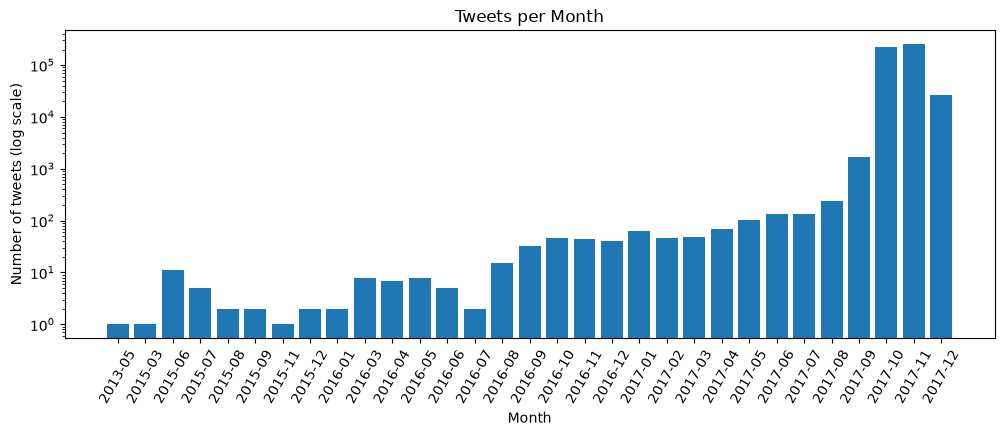

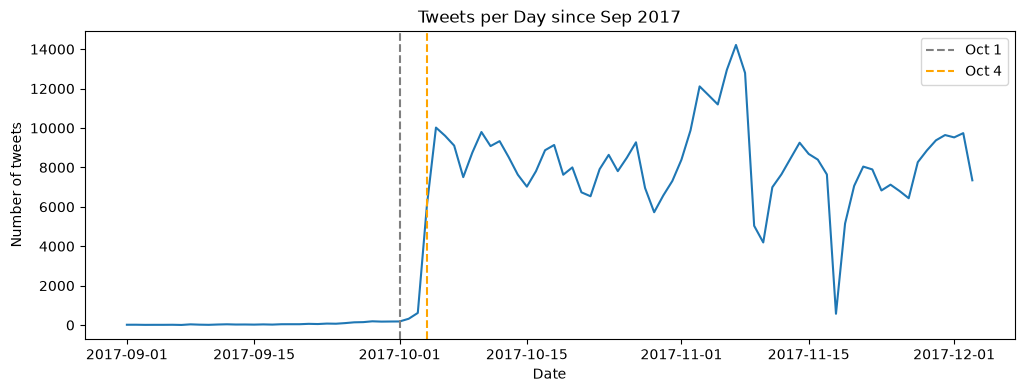

In [14]:
month_counts = pd.DataFrame({"Tweet Count": df["created_at"].dt.strftime("%Y-%m").value_counts().sort_index()})

plt.figure(figsize=(12, 4))
plt.bar(month_counts.index, month_counts["Tweet Count"])
plt.yscale("log")
plt.xticks(rotation=60)
plt.xlabel("Month")
plt.ylabel("Number of tweets (log scale)")
plt.title("Tweets per Month")
plt.show()

recent = df[df["created_at"] >= "2017-09-01"]
day_counts = recent["created_at"].dt.date.value_counts().sort_index()

plt.figure(figsize=(12, 4))
plt.plot(day_counts.index, day_counts.values)
plt.axvline(pd.Timestamp("2017-10-01"), color="gray", linestyle="--", label="Oct 1")
plt.axvline(pd.Timestamp("2017-10-04"), color="orange", linestyle="--", label="Oct 4")
plt.xlabel("Date")
plt.ylabel("Number of tweets")
plt.title("Tweets per Day since Sep 2017")
plt.legend()
plt.show()

Most tweets are from October to early December 2017. Before that, each month has only a few to a few hundred tweets.

- These early tweets are scattered. They were likely pulled in because later conversations replied to them.
- The daily count jumps from a few hundred to over 6,000 on Oct 4, 2017, so continuous data collection starts there.
- We keep tweets from Oct 4, 2017 onward and remove the earlier ones.
- Both events for RQ2 come after this date: the iOS 11.1 keyboard bug (Oct 31 - Nov 9) and Black Friday / Cyber Monday (Nov 24 - Nov 27). Oct 4 - Oct 30 can serve as a normal period for comparison.

In [15]:
print("Tweets before filtering:", df.shape[0])
df = df[df["created_at"] >= "2017-10-04"].copy()
print("Tweets after filtering:", df.shape[0])
print("Earliest tweet:", df["created_at"].min())

Tweets before filtering: 507873
Tweets after filtering: 504001
Earliest tweet: 2017-10-04 00:00:00+00:00


### 4. Pair Customer Tweets with Replies

A case is one customer tweet paired with the first brand reply to it.

- Split the tweets into customer tweets (`inbound == True`) and support tweets (`inbound == False`).
- Match a customer tweet's `tweet_id` to a support tweet's `in_response_to_tweet_id`. Columns from the two sides get the suffixes `_customer` and `_reply`.
- Keep only pairs where the reply author is the case's brand. A few customer tweets mention both brands, and we do not want the other brand's reply.
- If a customer tweet has several replies, keep the earliest one.
- Customer tweets with no reply are left out, since they have no waiting time.
- `is_first_tweet`: `True` if the customer tweet starts a conversation, `False` if it is a follow-up inside a conversation. We keep both kinds.
- `response_minutes`: the waiting time in minutes, from the customer tweet to the first brand reply.

In [16]:
customer = df[df["inbound"] == True]
support = df[df["inbound"] == False]

cases = customer.merge(support, left_on="tweet_id", right_on="in_response_to_tweet_id", suffixes=("_customer", "_reply"))
print("Customer-reply pairs:", cases.shape[0])

cases = cases[cases["author_id_reply"] == cases["related_brand_customer"]]
cases = cases.sort_values("created_at_reply").drop_duplicates("tweet_id_customer")
cases["is_first_tweet"] = cases["in_response_to_tweet_id_customer"].isna()
cases["response_minutes"] = (cases["created_at_reply"] - cases["created_at_customer"]).dt.total_seconds() / 60
print("Cases after keeping the first brand reply:", cases.shape[0])
cases[["tweet_id_customer", "tweet_id_reply", "created_at_customer", "created_at_reply", "related_brand_customer", "is_first_tweet", "response_minutes"]].head()

Customer-reply pairs: 221805
Cases after keeping the first brand reply: 209938


,tweet_id_customer,tweet_id_reply,created_at_customer,created_at_reply,related_brand_customer,is_first_tweet,response_minutes
97560,1286995,1286994,2017-10-04 00:04:13+00:00,2017-10-04 00:12:31+00:00,AmazonHelp,False,8.300000
97559,1286993,1286992,2017-10-04 00:24:40+00:00,2017-10-04 00:33:30+00:00,AmazonHelp,False,8.833333
16396,243032,243030,2017-10-04 00:07:40+00:00,2017-10-04 00:36:31+00:00,AppleSupport,True,28.850000
30847,387506,387504,2017-10-04 00:15:29+00:00,2017-10-04 00:37:54+00:00,AppleSupport,False,22.416667
16329,242530,242529,2017-10-04 00:32:37+00:00,2017-10-04 00:58:51+00:00,AppleSupport,True,26.233333


### 5. Check Response Time

Cases waiting more than 24 hours: 70


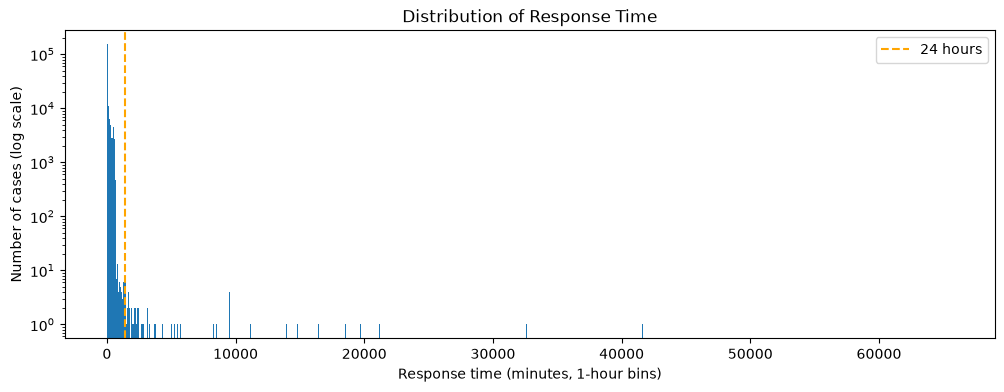

,Response Minutes
count,209938.000000
mean,80.908511
std,261.577345
min,0.766667
25%,9.250000
50%,21.966667
75%,71.400000
max,65653.433333


In [17]:
print("Cases waiting more than 24 hours:", (cases["response_minutes"] > 24 * 60).sum())

plt.figure(figsize=(12, 4))
plt.hist(cases["response_minutes"], bins=np.arange(0, cases["response_minutes"].max() + 60, 60))
plt.axvline(24 * 60, color="orange", linestyle="--", label="24 hours")
plt.yscale("log")
plt.xlabel("Response time (minutes, 1-hour bins)")
plt.ylabel("Number of cases (log scale)")
plt.title("Distribution of Response Time")
plt.legend()
plt.show()

pd.DataFrame({"Response Minutes": cases["response_minutes"].describe()})

Most cases get a reply within a few hours. Only 70 cases wait more than 24 hours, and they are spread thinly over a long tail up to about 45 days.

- These very late replies are unlikely to be a normal first response to the customer.
- They are only about 0.03% of the cases, but they pull the mean up.
- We remove cases that wait more than 24 hours, then plot the distribution again.

Cases before removing long waits: 209938
Cases after removing long waits: 209868


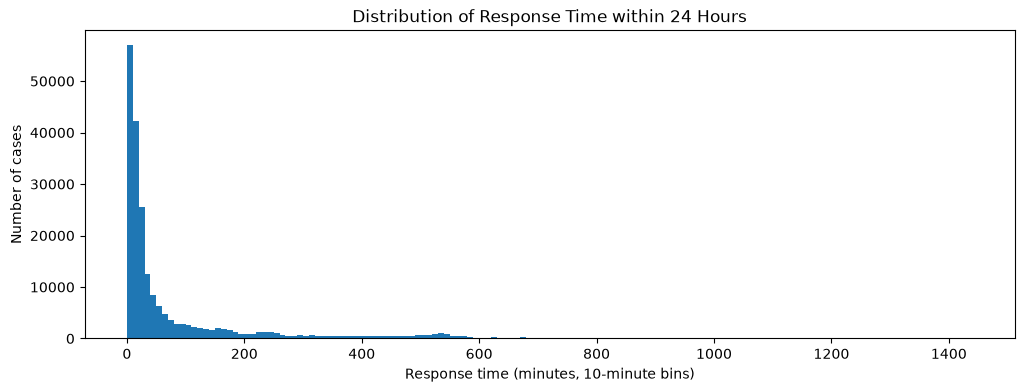

,Response Minutes
count,209868.000000
mean,78.561750
std,132.597261
min,0.766667
25%,9.250000
50%,21.950000
75%,71.283333
max,1435.466667


In [18]:
print("Cases before removing long waits:", cases.shape[0])
cases = cases[cases["response_minutes"] <= 24 * 60].copy()
print("Cases after removing long waits:", cases.shape[0])

plt.figure(figsize=(12, 4))
plt.hist(cases["response_minutes"], bins=np.arange(0, 24 * 60 + 10, 10))
plt.xlabel("Response time (minutes, 10-minute bins)")
plt.ylabel("Number of cases")
plt.title("Distribution of Response Time within 24 Hours")
plt.show()

pd.DataFrame({"Response Minutes": cases["response_minutes"].describe()})

### 6. Select Columns and Save

We keep the columns needed by the three research questions and give them clear names. Each row of `cases.pkl` is one case.

- `case_id`: the ID of the customer tweet. It is unique for each case.
- `brand`: the support account, `AmazonHelp` or `AppleSupport`.
- `customer_id`: the ID of the customer.
- `customer_text`: the text of the customer tweet.
- `created_at`: the time when the customer tweet was posted (UTC).
- `is_first_tweet`: whether the customer tweet starts a conversation.
- `reply_tweet_id`: the ID of the first brand reply.
- `reply_text`: the text of the first brand reply.
- `reply_at`: the time when the first brand reply was posted (UTC).
- `response_minutes`: the waiting time in minutes, from `created_at` to `reply_at`.

In [19]:
new_names = {
    "tweet_id_customer": "case_id",
    "related_brand_customer": "brand",
    "author_id_customer": "customer_id",
    "text_customer": "customer_text",
    "created_at_customer": "created_at",
    "is_first_tweet": "is_first_tweet",
    "tweet_id_reply": "reply_tweet_id",
    "text_reply": "reply_text",
    "created_at_reply": "reply_at",
    "response_minutes": "response_minutes",
}
cases = cases[list(new_names.keys())].rename(columns=new_names)
cases = cases.sort_values("created_at").reset_index(drop=True)

cases.to_pickle("../data/cases.pkl")
print("Saved", cases.shape[0], "cases to ../data/cases.pkl")
cases.head()

Saved 209868 cases to ../data/cases.pkl


,case_id,brand,customer_id,customer_text,created_at,is_first_tweet,reply_tweet_id,reply_text,reply_at,response_minutes
0,193661,AppleSupport,161535,@AppleSupport Yes I’m able to open safari but ...,2017-10-04 00:03:07+00:00,False,193660,@161535 Understood! Can you tell us the versio...,2017-10-04 00:59:51+00:00,56.733333
1,1286995,AmazonHelp,421025,"@AmazonHelp I can't explain in 140 c, that's w...",2017-10-04 00:04:13+00:00,False,1286994,@421025 You can send us a direct message if yo...,2017-10-04 00:12:31+00:00,8.300000
2,243032,AppleSupport,173714,Apple Podcast is not played continuously on #i...,2017-10-04 00:07:40+00:00,True,243030,@173714 Let's see if we can keep your podcasts...,2017-10-04 00:36:31+00:00,28.850000
3,387506,AppleSupport,207722,@AppleSupport I did that yesterday.,2017-10-04 00:15:29+00:00,False,387504,"@207722 Which iPhone do you have, and what's t...",2017-10-04 00:37:54+00:00,22.416667
4,1286993,AmazonHelp,421025,"@AmazonHelp I found the email, never mind.",2017-10-04 00:24:40+00:00,False,1286992,@421025 No problem! Anytime you need assistanc...,2017-10-04 00:33:30+00:00,8.833333
